# 03. Финальная мультимодальная модель и экспорт дашборда

**Цель ноутбука.** Зафиксировать финальную модель как единую мультимодальную систему: log branch + KPI branch + masks + fusion + heads. Ноутбук объясняет архитектуру, показывает команду обучения, читает метрики train-run и экспортирует bundle для replay-дашборда.

**Важно.** Дашборд не использует целевые метки как score. Он получает score модели, затем alert-layer переводит его в состояния `Норма`, `Наблюдение`, `Тревога`, `Инцидент`.


In [1]:
from pathlib import Path
import json
import os
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from dashboard.final_data_pipeline import PROJECT_ROOT, artifact_paths
from dashboard.export_dashboard_bundle import export_bundle

ARTIFACT_DIR = PROJECT_ROOT / "dashboard" / "artifacts"
PATHS = artifact_paths(ARTIFACT_DIR)
RUN_ID = "final_multimodal_strict_intensity_gap10"
MODEL_RUN_DIR = PATHS.model_dir / RUN_ID
RUN_TRAIN = os.environ.get("RUN_FINAL_TRAIN", "0") == "1"

plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

train_command = [
    sys.executable,
    "-m", "dashboard.train_multimodal_fusion",
    "--contract", str(PATHS.contract_path),
    "--artifact-dir", str(ARTIFACT_DIR),
    "--run-id", RUN_ID,
    "--seeds", "42,43,44",
]
print("Команда обучения:")
print(" ".join(map(str, train_command)))
print("RUN_FINAL_TRAIN =", RUN_TRAIN)


Команда обучения:
C:\Users\ipopi\AppData\Local\Programs\Python\Python313\python.exe -m dashboard.train_multimodal_fusion --contract C:\Main\DGTU\ВКР\Diploma\dashboard\artifacts\contract\strict_intensity_contract.csv.gz --artifact-dir C:\Main\DGTU\ВКР\Diploma\dashboard\artifacts --run-id final_multimodal_strict_intensity_gap10 --seeds 42,43,44
RUN_FINAL_TRAIN = False


## 1. Модельная постановка

Вход модели состоит из трех частей:

1. **Логовая ветвь** — top log events в контексте текущего окна.
2. **KPI-ветвь** — последовательность KPI-признаков за несколько предыдущих окон.
3. **Маски доступности** — признаки того, какие модальности реально присутствуют.

Выход модели содержит несколько голов: бинарные `warning/risk`, intensity-головы и вспомогательные heads. Для дашборда основной практический score строится из `warning_intensity_score`, а диагностический strict risk-channel — из `state_score`.


In [2]:
architecture = pd.DataFrame([
    {"Блок": "Log branch", "Вход": "Top log events", "Назначение": "Текстовые симптомы и шаблоны ошибок"},
    {"Блок": "KPI branch", "Вход": "KPI sequence", "Назначение": "Физическое состояние системы во времени"},
    {"Блок": "Modality masks", "Вход": "log/kpi availability", "Назначение": "Явное кодирование пропусков модальностей"},
    {"Блок": "Fusion block", "Вход": "log hidden + KPI hidden + masks", "Назначение": "Единое мультимодальное решение"},
    {"Блок": "Binary heads", "Вход": "fused hidden", "Назначение": "Строгие цели warning/risk"},
    {"Блок": "Intensity heads", "Вход": "fused hidden", "Назначение": "Нарастание риска по lead time"},
])
display(architecture)


,Блок,Вход,Назначение
0,Log branch,Top log events,Текстовые симптомы и шаблоны ошибок
1,KPI branch,KPI sequence,Физическое состояние системы во времени
2,Modality masks,log/kpi availability,Явное кодирование пропусков модальностей
3,Fusion block,log hidden + KPI hidden + masks,Единое мультимодальное решение
4,Binary heads,fused hidden,Строгие цели warning/risk
5,Intensity heads,fused hidden,Нарастание риска по lead time


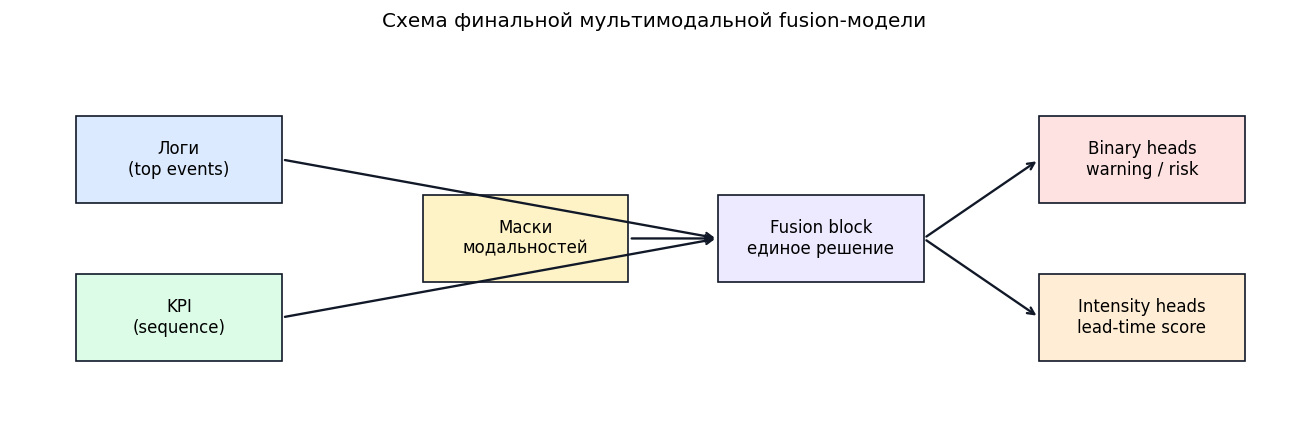

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.axis("off")

boxes = [
    (0.05, 0.58, "Логи\n(top events)", "#dbeafe"),
    (0.05, 0.18, "KPI\n(sequence)", "#dcfce7"),
    (0.32, 0.38, "Маски\nмодальностей", "#fef3c7"),
    (0.55, 0.38, "Fusion block\nединое решение", "#ede9fe"),
    (0.80, 0.58, "Binary heads\nwarning / risk", "#fee2e2"),
    (0.80, 0.18, "Intensity heads\nlead-time score", "#ffedd5"),
]
for x, y, label, color in boxes:
    rect = plt.Rectangle((x, y), 0.16, 0.22, facecolor=color, edgecolor="#111827", linewidth=1.0)
    ax.add_patch(rect)
    ax.text(x + 0.08, y + 0.11, label, ha="center", va="center", fontsize=10)

arrows = [
    ((0.21, 0.69), (0.55, 0.49)),
    ((0.21, 0.29), (0.55, 0.49)),
    ((0.48, 0.49), (0.55, 0.49)),
    ((0.71, 0.49), (0.80, 0.69)),
    ((0.71, 0.49), (0.80, 0.29)),
]
for start, end in arrows:
    ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="->", lw=1.4, color="#111827"))

ax.set_title("Схема финальной мультимодальной fusion-модели", fontsize=12)
plt.tight_layout()
plt.show()


**Локальный вывод.** Модель является одной fused-системой, а не набором независимых log-only и KPI-only моделей. Отдельные baseline используются только для сравнения и диагностики.


## 2. Конфигурация обучения

Обучение вынесено в Python-модуль, чтобы ноутбук оставался воспроизводимой витриной, а не большим скриптом. По умолчанию тяжелое обучение не запускается автоматически. Для запуска внутри ноутбука нужно выставить `RUN_FINAL_TRAIN=1`; для машины с GPU рекомендуется запускать команду из терминала.


In [4]:
training_config = pd.DataFrame(
    [
        {"Параметр": "Contract", "Значение": str(PATHS.contract_path.relative_to(PROJECT_ROOT))},
        {"Параметр": "Artifact dir", "Значение": str(ARTIFACT_DIR.relative_to(PROJECT_ROOT))},
        {"Параметр": "Run id", "Значение": RUN_ID},
        {"Параметр": "Seeds", "Значение": "42, 43, 44"},
        {"Параметр": "GPU-режим", "Значение": "--device cuda"},
        {"Параметр": "Текстовый backend", "Значение": "tfidf по умолчанию; embeddinggemma для полного запуска"},
    ]
)
display(training_config)


,Параметр,Значение
0,Contract,dashboard\artifacts\contract\strict_intensity_...
1,Artifact dir,dashboard\artifacts
2,Run id,final_multimodal_strict_intensity_gap10
3,Seeds,"42, 43, 44"
4,GPU-режим,--device cuda
5,Текстовый backend,tfidf по умолчанию; embeddinggemma для полного...


In [5]:
if RUN_TRAIN:
    subprocess.run(train_command, check=True)
elif MODEL_RUN_DIR.exists():
    print(f"Найден готовый train-run: {MODEL_RUN_DIR.relative_to(PROJECT_ROOT)}")
else:
    print("Train-run пока не найден. Запустите команду обучения выше или установите RUN_FINAL_TRAIN=1.")


Train-run пока не найден. Запустите команду обучения выше или установите RUN_FINAL_TRAIN=1.


**Локальный вывод.** Такая организация разделяет исследовательский документ и исполняемый pipeline. Если модель будет заменена, contract, exporter и dashboard останутся совместимыми.


## 3. Динамика обучения

Если train-run уже выполнен, анализируются истории по seed: функция потерь, validation AP и monitoring-score. Это нужно, чтобы показать не только итоговую цифру, но и характер обучения: где модель сходится, где возникает ранняя остановка и насколько устойчивы результаты.


In [6]:
history_files = sorted(MODEL_RUN_DIR.glob("history_seed*.csv")) if MODEL_RUN_DIR.exists() else []
if history_files:
    history = pd.concat([pd.read_csv(path) for path in history_files], ignore_index=True)
    display(history.groupby("seed").agg(эпохи=("epoch", "max"), лучший_monitor=("best_score", "max")).reset_index())

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for seed, part in history.groupby("seed"):
        axes[0].plot(part["epoch"], part["train_loss"], label=f"seed {seed}")
        axes[1].plot(part["epoch"], part["monitor_score"], label=f"seed {seed}")
    axes[0].set_title("Динамика train loss")
    axes[0].set_xlabel("Эпоха")
    axes[0].set_ylabel("Loss")
    axes[1].set_title("Validation monitoring-score")
    axes[1].set_xlabel("Эпоха")
    axes[1].set_ylabel("Score")
    axes[0].legend()
    axes[1].legend()
    plt.tight_layout()
    plt.show()
else:
    print("История обучения пока отсутствует.")


История обучения пока отсутствует.


## 4. Итоговые метрики модели

Основная метрика для ranking-качества — Average Precision. Для dashboard дополнительно важны top-k precision/lift и run-level alert-поведение, потому что пользователю важен не только score окна, но и момент тревоги относительно сбоя.


In [7]:
metrics_path = MODEL_RUN_DIR / "ensemble_metrics.csv"
baseline_path = MODEL_RUN_DIR / "baseline_comparison.csv"
if metrics_path.exists():
    metrics = pd.read_csv(metrics_path)
    focus = metrics.loc[
        metrics["score"].isin(["warning_intensity_score", "risk_intensity_score", "state_score"]),
        ["target", "model", "score", "average_precision", "roc_auc", "precision", "recall", "f1"],
    ].rename(
        columns={
            "target": "Цель",
            "model": "Модель",
            "score": "Score",
            "average_precision": "Average Precision",
            "roc_auc": "ROC AUC",
            "precision": "Precision",
            "recall": "Recall",
            "f1": "F1",
        }
    )
    display(focus)
else:
    print("Метрики модели пока не найдены.")

if baseline_path.exists():
    baseline = pd.read_csv(baseline_path)
    display(baseline.sort_values(["target", "average_precision"], ascending=[True, False]))
else:
    print("Baseline comparison train-run пока не найден.")


Метрики модели пока не найдены.
Baseline comparison train-run пока не найден.


In [8]:
if metrics_path.exists() and baseline_path.exists():
    metrics_raw = pd.read_csv(metrics_path)
    baseline_raw = pd.read_csv(baseline_path)
    model_rows = metrics_raw.loc[
        ((metrics_raw["target"].eq("y_warning")) & (metrics_raw["score"].eq("warning_intensity_score")))
        | ((metrics_raw["target"].eq("y_risk")) & (metrics_raw["score"].eq("state_score")))
    ].copy()
    model_rows["baseline"] = "финальная модель"
    model_rows = model_rows[["target", "baseline", "average_precision"]]
    best_baseline = (
        baseline_raw.sort_values("average_precision", ascending=False)
        .groupby("target", as_index=False)
        .head(1)[["target", "baseline", "average_precision"]]
    )
    compare = pd.concat([model_rows, best_baseline], ignore_index=True)
    display(compare)

    fig, ax = plt.subplots(figsize=(7, 3.8))
    labels = compare["target"] + " / " + compare["baseline"]
    ax.bar(labels, compare["average_precision"], color=["#7c3aed" if b == "финальная модель" else "#64748b" for b in compare["baseline"]])
    ax.set_title("Сравнение финальной модели с лучшим baseline")
    ax.set_ylabel("Average Precision")
    ax.set_xlabel("Вариант")
    ax.tick_params(axis="x", rotation=25)
    plt.tight_layout()
    plt.show()
else:
    print("Сравнение с baseline появится после полного train-run.")


Сравнение с baseline появится после полного train-run.


**Локальный вывод.** Победа модели должна формулироваться честно: если binary risk слабый, это ограничение фиксируется. Практическая ценность переносится в alert-layer и ranking ранней деградации, а не в обещание идеального бинарного предсказателя.


## 5. Ranking-диагностика и slice-анализ

Top-k precision показывает, насколько полезны самые высокие score. Slice-анализ проверяет, не возникает ли ситуация, когда модель работает только на одном workload или только при наличии обеих модальностей.


In [9]:
ranking_path = MODEL_RUN_DIR / "ranking_diagnostics.csv"
slice_path = MODEL_RUN_DIR / "slice_metrics.csv"

if ranking_path.exists():
    ranking = pd.read_csv(ranking_path)
    display(ranking.head(20))
    part = ranking.loc[(ranking["split"].eq("test")) & (ranking["score"].isin(["warning_intensity_score", "state_score"]))]
    if not part.empty:
        fig, ax = plt.subplots(figsize=(8, 3.8))
        for (target, score), group in part.groupby(["target", "score"]):
            ax.plot(group["top_fraction"], group["precision_at_top"], marker="o", label=f"{target} / {score}")
        ax.set_title("Precision в верхней части ранжирования")
        ax.set_xlabel("Доля верхних окон")
        ax.set_ylabel("Precision@top")
        ax.legend()
        plt.tight_layout()
        plt.show()
else:
    print("Ranking diagnostics пока отсутствует.")

if slice_path.exists():
    slices = pd.read_csv(slice_path)
    display(slices)
else:
    print("Slice metrics пока отсутствуют.")


Ranking diagnostics пока отсутствует.
Slice metrics пока отсутствуют.


## 6. Экспорт replay bundle

После обучения exporter объединяет prediction store с contract, считает alert-layer и записывает bundle для дашборда. В дашборд передаются только модельные score и диагностические признаки; label используется только для оценки и разметки фактического инцидента.


In [10]:
if (MODEL_RUN_DIR / "ensemble_predictions.csv").exists() and PATHS.contract_path.exists():
    report = export_bundle(model_run_dir=MODEL_RUN_DIR, contract_path=PATHS.contract_path, out_dir=PATHS.bundle_dir)
    print(json.dumps(
        {
            "bundle_dir": str(PATHS.bundle_dir.relative_to(PROJECT_ROOT)),
            "model_name": report.get("model_name"),
            "score_source": report.get("score_source"),
            "proxy_fallback_windows": report.get("proxy_fallback_windows"),
        },
        ensure_ascii=False,
        indent=2,
    ))
else:
    print("Bundle не экспортирован: сначала нужен train-run модели и contract из 02.")


Bundle не экспортирован: сначала нужен train-run модели и contract из 02.


In [11]:
bundle_files = [
    PATHS.bundle_dir / "replay_bundle.csv.gz",
    PATHS.bundle_dir / "dashboard_model_report.json",
    PATHS.bundle_dir / "baseline_comparison.csv",
    PATHS.bundle_dir / "alert_events.csv",
    PATHS.bundle_dir / "metrics_summary.csv",
    PATHS.bundle_dir / "model_card_product.md",
]
bundle_table = pd.DataFrame(
    [
        {
            "Файл": path.name,
            "Найден": path.exists(),
            "Путь": str(path.relative_to(PROJECT_ROOT)),
        }
        for path in bundle_files
    ]
)
display(bundle_table)


,Файл,Найден,Путь
0,replay_bundle.csv.gz,False,dashboard\artifacts\bundle\replay_bundle.csv.gz
1,dashboard_model_report.json,False,dashboard\artifacts\bundle\dashboard_model_rep...
2,baseline_comparison.csv,False,dashboard\artifacts\bundle\baseline_comparison...
3,alert_events.csv,False,dashboard\artifacts\bundle\alert_events.csv
4,metrics_summary.csv,False,dashboard\artifacts\bundle\metrics_summary.csv
5,model_card_product.md,False,dashboard\artifacts\bundle\model_card_product.md


**Итоговый вывод.** Финальный результат этапа — не только обученная модель, но и воспроизводимый bundle для интерфейса. Это делает проект похожим на лабораторный продукт: данные проходят путь от raw logs/KPI до replay-дашборда с alert-layer.
